### 1. Import das bibliotecas e definição da função de leitura

In [1]:
import requests
import pandas as pd

def read_ckan_sql(resource_id):
    url = "https://dados.uffs.edu.br/api/3/action/datastore_search_sql"

    limit = 1000
    offset = 0
    all_records = []

    while True:
        sql = f'''
        SELECT *
        FROM "{resource_id}"
        LIMIT {limit}
        OFFSET {offset}
        '''

        response = requests.get(url, params={"sql": sql})
        data = response.json()

        records = data["result"]["records"]

        if not records:
            break

        all_records.extend(records)
        offset += limit

        print(f"Baixados: {offset}")

    df = pd.DataFrame(all_records)
    return df

### 2. Passa o id dos dados pra função de leitura, e transforma o resultado em um dataframe pandas

In [3]:
df_alunos_bruto = read_ckan_sql("bee823cd-7826-4dc6-95f7-dd13dfe609f3")
print("Número de registros:", len(df_alunos_bruto))

Baixados: 1000
Baixados: 2000
Baixados: 3000
Baixados: 4000
Baixados: 5000
Baixados: 6000
Baixados: 7000
Baixados: 8000
Baixados: 9000
Baixados: 10000
Baixados: 11000
Baixados: 12000
Baixados: 13000
Baixados: 14000
Baixados: 15000
Baixados: 16000
Baixados: 17000
Baixados: 18000
Baixados: 19000
Baixados: 20000
Baixados: 21000
Baixados: 22000
Baixados: 23000
Baixados: 24000
Baixados: 25000
Baixados: 26000
Baixados: 27000
Baixados: 28000
Baixados: 29000
Baixados: 30000
Baixados: 31000
Baixados: 32000
Baixados: 33000
Baixados: 34000
Baixados: 35000
Baixados: 36000
Baixados: 37000
Baixados: 38000
Baixados: 39000
Baixados: 40000
Baixados: 41000
Baixados: 42000
Baixados: 43000
Número de registros: 42301


### 3. Mostra os 5 primeiros registros

In [4]:
df_alunos_bruto.head()

,_id,_full_text,tipo_discente,raca,genero,ano_ingresso,semestre_ingresso,forma_ingresso,modalidade_inscricao,modalidade_vaga_ocupada,sit_matricula,nome_campus,cod_uffs,nome_curso,turno,matriz,data_atualizacao
0,1,'-04':15 '-13':16 '15.680636':19 '1600':10 '2'...,REGULAR,Indígeno,M,2026,2,PIN,N/A,None,ATIVO,Chapecó,1600,Administração,Noturno,2017/2,2026-04-13T02:30:15.680636
1,2,'-04':18 '-13':19 '1':5 '1400':11 '15.680636':...,REGULAR,Branco,F,2026,1,SiSU,LI_EP,None,ATIVO,Chapecó,1400,Enfermagem,Matutino e Vespertino,2025/1,2026-04-13T02:30:15.680636
2,3,'-04':17 '-13':18 '1':5 '15.680636':21 '2022/1...,REGULAR,Branco,F,2026,1,PROCESSO SELETIVO SIMPLIFICADO,N/A,None,ATIVO,Realeza,3704,Pedagogia,Noturno,2022/1,2026-04-13T02:30:15.680636
3,4,'-04':19 '-13':20 '1':5 '15.680636':23 '1720':...,REGULAR,Branco,M,2026,1,RETORNO DE ALUNO-ABANDONO,N/A,None,ATIVO,Chapecó,1720,História,Noturno,2013/2,2026-04-13T02:30:15.680636
4,5,'-04':15 '-13':16 '1':6 '15.680636':19 '2026':...,ESPECIAL,Não Informado,M,2026,1,ALUNO ESPECIAL EM MOBILIDADE,N/A,None,ATIVO,Chapecó,NaN,NaN,NaN,NaN,2026-04-13T02:30:15.680636


### 4. Leitura do dicionário de dados do arquivo

In [5]:
df_dicionario_dados = read_ckan_sql("5ff2919d-ca1c-4bc0-bb71-6a1ffd1b9918")
print("Número de registros:", len(df_dicionario_dados))

Baixados: 1000
Número de registros: 15


### 5. Mostra os registros

In [6]:
df_dicionario_dados

,_id,_full_text,coluna,tipo,rotulo,descricao
0,1,"'ccrs':31 'curs':23,30 'discent':2,6,8 'especi...",tipo_discente,text,Tipo de Discente,O discente pode ser regular (quando forma vínc...
1,2,"'estud':6 'rac':1,3,4 'text':2",raca,text,Raça,Raça do estudante.
2,3,'estud':7 'gener':1 'gêner':3 'sexo/g':4 'text...,genero,text,Gênero,Sexo/gênero do estudante.
3,4,"'ano':1,4,7 'curs':13 'estud':11 'ingress':2,6...",ano_ingresso,integer,Ano de ingresso,Ano de ingresso do estudante no curso.
4,5,"'curs':13 'estud':11 'ingress':2,6,9 'integ':3...",semestre_ingresso,integer,Semestre de Ingresso,Semestre de ingresso do estudante no curso.
5,6,"'curs':13 'estud':11 'exempl':15 'form':1,4,7 ...",forma_ingresso,text,Forma de ingresso,"Forma de ingresso do estudante no curso, por e..."
6,7,"'/2012':71,108,134,165,199,238,266,299 '1':53,...",modalidade_inscricao,text,Modalidade de inscrição,Nem todas as formas de ingresso possuem modali...
7,8,"'ac':44 'além':35 'ampla':42 'candidat':20,48 ...",modalidade_vaga_ocupada,text,Modalidade da Vaga Ocupada,Para as modalidades de ingresso que possuem co...
8,9,'curs':13 'estud':11 'matricul':2 'matrícul':6...,sit_matricula,text,Situação de matrícula,Situação de matrícula do estudante no curso.
9,10,"'campus':2,6,7 'curs':11 'nom':1,4 'ofert':9 '...",nome_campus,text,Nome do campus,Campus de oferta do curso.


### Funções úteis

In [7]:
# 1. Função para formatar o número no padrão moeda do Brasil
from pandas.io.formats.style import Styler
def formatar_moeda_br(valor):
    if pd.isna(valor):
        return "R$ 0,00"
    
    # Formata com 2 casas decimais no padrão americano (ex: 1,234,567.89)
    valor_str = f"{valor:,.2f}"
    
    # Troca a vírgula por um 'X' temporário, o ponto por vírgula, e o 'X' por ponto
    valor_br = valor_str.replace(",", "X").replace(".", ",").replace("X", ".")
    
    return f"R$ {valor_br}"

## Análises iniciais

C:\Users\marco\AppData\Local\Temp\ipykernel_12712\199734826.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sit_counts.values, y=sit_counts.index, palette=cores)


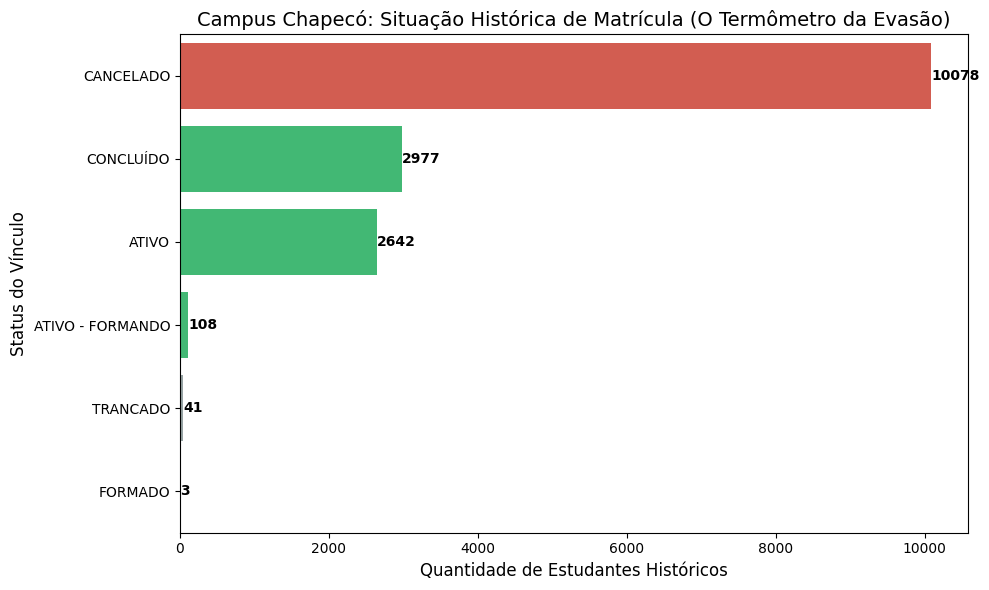

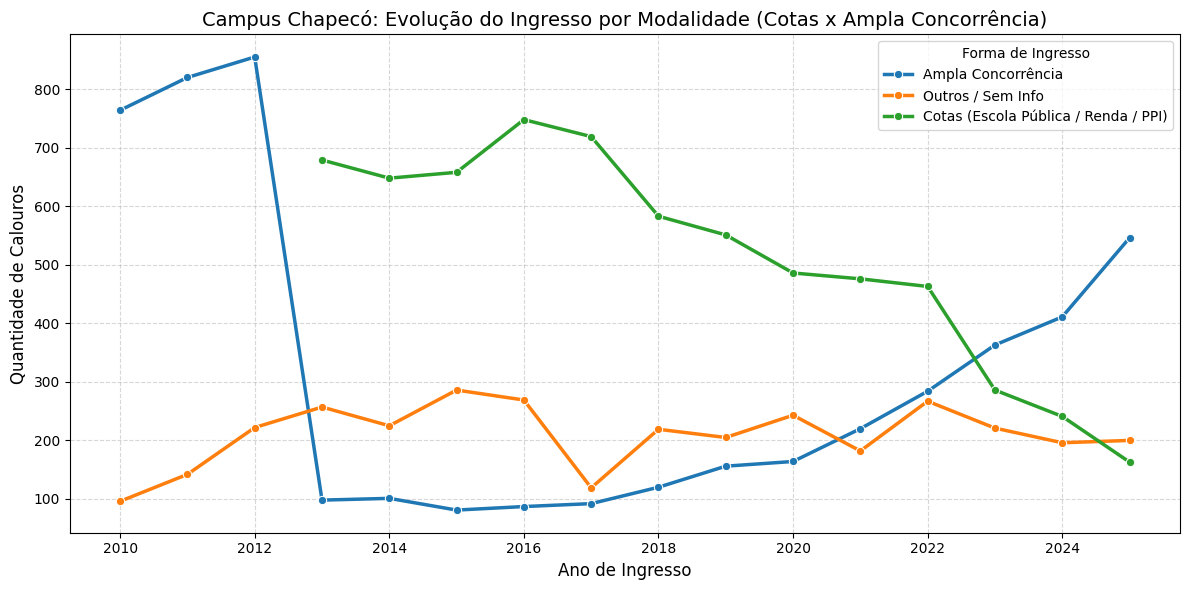

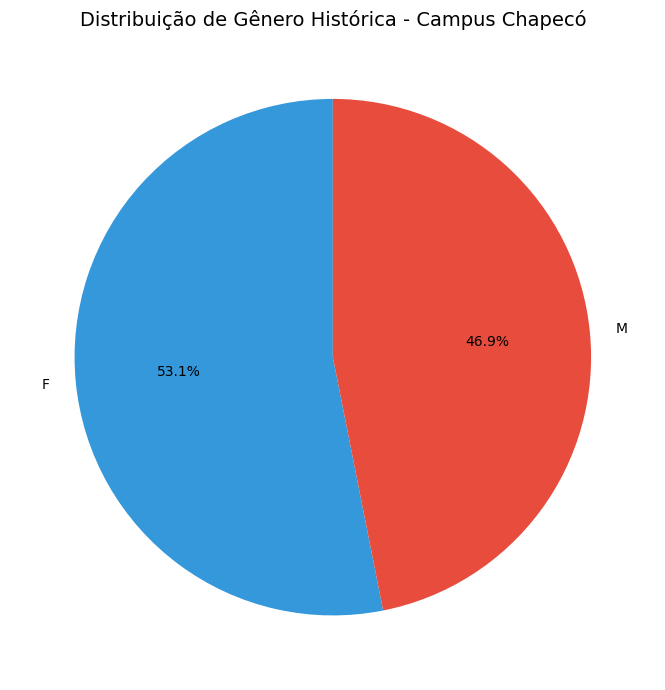

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 0. A Mágica do Escopo (Filtramos Chapecó e pegamos apenas alunos Regulares)
# Alunos 'Especiais' geralmente fazem 1 matéria e saem, o que sujaria nossa taxa de evasão
df_chapeco = df_alunos_bruto[
    (df_alunos_bruto['nome_campus'] == 'Chapecó') & 
    (df_alunos_bruto['tipo_discente'].str.upper() == 'REGULAR')
].copy()

# ---------------------------------------------------------
# ANÁLISE 1: O "Funil" de Situação (Evasão vs Formatura)
# ---------------------------------------------------------
# Vamos ver como estão os alunos historicamente
plt.figure(figsize=(10, 6))
sit_counts = df_chapeco['sit_matricula'].value_counts()

# Colorindo de verde o que é bom (Ativo/Formado) e vermelho o que é ruim (Cancelado/Desistente)
cores = ['#2ecc71' if 'ATIVO' in str(x).upper() or 'FORMADO' in str(x).upper() or 'CONCLU' in str(x).upper() 
         else '#e74c3c' if 'CANCELADO' in str(x).upper() or 'DESIST' in str(x).upper() 
         else '#95a5a6' for x in sit_counts.index]

sns.barplot(x=sit_counts.values, y=sit_counts.index, palette=cores)
plt.title('Campus Chapecó: Situação Histórica de Matrícula (O Termômetro da Evasão)', fontsize=14)
plt.xlabel('Quantidade de Estudantes Históricos', fontsize=12)
plt.ylabel('Status do Vínculo', fontsize=12)

# Adicionando número exato na barra
for i, valor in enumerate(sit_counts.values):
    plt.text(valor + 5, i, str(valor), va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANÁLISE 2: Evolução da Diversidade (Cotas vs AC ao longo do tempo)
# ---------------------------------------------------------
# Vamos simplificar as cotas: Ou é Ampla Concorrência (AC) ou é Cota (Qualquer L ou A)
def simplificar_cota(cota):
    if pd.isna(cota) or cota == 'N/A':
        return 'Outros / Sem Info'
    elif 'AC' in str(cota):
        return 'Ampla Concorrência'
    else:
        return 'Cotas (Escola Pública / Renda / PPI)'

df_chapeco['grupo_cota'] = df_chapeco['modalidade_inscricao'].apply(simplificar_cota)

agrupado_cota = df_chapeco.groupby(['ano_ingresso', 'grupo_cota']).size().reset_index(name='qtd')
agrupado_cota = agrupado_cota[(agrupado_cota['ano_ingresso'] >= 2010) & (agrupado_cota['ano_ingresso'] <= 2025)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=agrupado_cota, x='ano_ingresso', y='qtd', hue='grupo_cota', marker='o', linewidth=2.5)
plt.title('Campus Chapecó: Evolução do Ingresso por Modalidade (Cotas x Ampla Concorrência)', fontsize=14)
plt.xlabel('Ano de Ingresso', fontsize=12)
plt.ylabel('Quantidade de Calouros', fontsize=12)
plt.legend(title='Forma de Ingresso')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANÁLISE 3: Gênero no Campus Chapecó
# ---------------------------------------------------------
genero_counts = df_chapeco['genero'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(genero_counts.values, labels=genero_counts.index, autopct='%1.1f%%', 
        colors=['#3498db', '#e74c3c', '#f1c40f', '#9b59b6'], startangle=90)
plt.title('Distribuição de Gênero Histórica - Campus Chapecó', fontsize=14)
plt.tight_layout()
plt.show()